In [1]:
 # Required packages
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

import scipy.sparse as sp

## Data loading
##### L2, TR1, TR2 (Europarl) and NN (Non-native Europarl) — 5-sentence chunks, 520 per dataset per language

| dataset_name | Corpus | Text type |
|---|---|---|
| L2 | L2 | learner essays (non-native English) |
| TR1 | TR | thesis abstracts translated into English |
| TR2 | Europarl | EP speeches translated into English |
| NN | Non-native Europarl | EP speeches given in English by non-native MEPs |

In [2]:
# 520 chunks per dataset and per language (all_corpora_520.csv)

data = pd.read_csv("all_corpora_520.csv")

DATASET_NAMES = {"L2": "L2", "TR": "TR1", "Europarl": "TR2", "Non-native Europarl": "NN"}

df = data.drop(columns=["afile", "group", "sentlength"], axis="columns")
df = df.rename(columns={"language": "L1"})
df["dataset_name"] = df.pop("corpus").map(DATASET_NAMES)

num_cols = df.select_dtypes(include='number').columns
numerical_cols = [c for c in num_cols if c not in ['L1']]
print("Numeric feature columns:", numerical_cols)

# Count of L1 per dataset
count_per_L2 = df.groupby("dataset_name")["L1"].value_counts().unstack(fill_value=0)

print(count_per_L2)

L2 = df[df['dataset_name'] == 'L2']
TR1 = df[df['dataset_name'] == 'TR1']
TR2 = df[df['dataset_name'] == 'TR2']
NN = df[df['dataset_name'] == 'NN']

Numeric feature columns: ['ppron', 'possdet', 'indef', 'cconj', 'whconj', 'relativ', 'pied', 'correl', 'copula', 'attrib', 'pasttense', 'lexdens', 'lexTTR', 'mquantif', 'mpred', 'finites', 'infs', 'pverbals', 'deverbals', 'bypassives', 'longpassives', 'sconj', 'addit', 'advers', 'caus', 'tempseq', 'epist', 'but', 'comp', 'sup', 'neg', 'numcls', 'simple', 'demdets', 'nnargs', 'mhd', 'mdd', 'acl', 'aux', 'aux:pass', 'ccomp', 'nsubj:pass', 'parataxis', 'xcomp']
L1             de   es   fr   it
dataset_name                    
L2            520  520  520  520
NN            520  520  520  520
TR1           520  520  520  520
TR2           520  520  520  520


# RQ1: How well can we recognize the L1 of a text using supervised ML?
One MLP trained on all four datasets together (80/20 stratified split) predicts the L1 (de / es / fr / it). Chance level = 0.25.

In [3]:
import scipy.sparse as sp
from sklearn.metrics import confusion_matrix


def run_nn(df, features, label_col="L1", title="Neural Network"):


    X = df[features].values
    y = df[label_col].values

    if y.dtype.kind in {'O', 'U', 'S'}:  # string/object
        le = LabelEncoder()
        y = le.fit_transform(y)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    print(f"Length: {len(df)}, Train: {len(X_train)}, Test: {len(X_test)}")

    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)

    # Ensure X is dense float64

    def to_dense_float(a):
        if sp.issparse(a):
            a = a.toarray()
        return np.asarray(a, dtype=np.float64)

    X_train_s = to_dense_float(X_train_s)
    X_test_s  = to_dense_float(X_test_s)


    # Ensure y is a plain 1D array (not sparse, not weird dtype)
    y_train = np.asarray(y_train)
    y_test  = np.asarray(y_test)


    mlp = MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        max_iter=200,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=42
    )
    mlp.fit(X_train_s, y_train)

    y_pred = mlp.predict(X_test_s)

    accuracy = accuracy_score(y_test, y_pred)
    print(f"\n===== {title} =====")
    print("Test Accuracy:", accuracy)

    cm = confusion_matrix(y_test, y_pred)

    label_map = {0: "de", 1: "es", 2: "fr", 3: "it"}

    labels = sorted(label_map.keys())
    target_names = [label_map[i] for i in labels]

    print(
        "\nClassification Report:\n",
        classification_report(
            y_test,
            y_pred,
            labels=labels,
            target_names=target_names,
            digits=4
        )
    )

    # The LabelEncoder may re-order classes, so use le.classes_
    # and convert them back to original coded labels
    classes = le.classes_                    # e.g. ["de","es","fr","it"]
    classes_int = le.transform(classes)      # e.g. [0,1,2,3]
    classes_str = [label_map[i] for i in classes_int]

    print("\nConfusion matrix:")
    print(cm)

    plt.figure(figsize=(8,6))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=classes_str,
        yticklabels=classes_str
    )
    plt.title(f"Confusion Matrix: {title}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()


    return mlp, accuracy, cm

In [4]:
# every dataset already has 520 rows per L1 -> min_count = 520 (no further downsampling)
min_count = L2["L1"].value_counts().min()

# Downsample each class L2 to that size
L2 = (
    L2
    .groupby('L1', group_keys=False)
    .sample(n=min_count, random_state=42)
)

#----------------------------------------------
min_count = TR1["L1"].value_counts().min()

# Downsample each class to that size
TR1 = (
    TR1
    .groupby('L1', group_keys=False)
    .sample(n=min_count, random_state=42)
)
TR1 = TR1.dropna()



#------------------------------------------------
min_count = TR2["L1"].value_counts().min()

# Downsample each class to that size
TR2 = (
    TR2
    .groupby('L1', group_keys=False)
    .sample(n=min_count, random_state=42)
)

#------------------------------------------------
min_count = NN["L1"].value_counts().min()

# Downsample each class to that size
NN = (
    NN
    .groupby('L1', group_keys=False)
    .sample(n=min_count, random_state=42)
)


#-------------------------------------------------
TR1.loc[:, "dataset_name"] = "TR1"
TR2.loc[:, "dataset_name"] = "TR2"
L2.loc[:, "dataset_name"] = "L2"
NN.loc[:, "dataset_name"] = "NN"


df = pd.concat([TR1, L2, TR2, NN], axis=0, ignore_index=True)

Length: 8320, Train: 6656, Test: 1664



===== MLP Classification of all dataset(Test set) =====
Test Accuracy: 0.42127403846153844

Classification Report:
               precision    recall  f1-score   support

          de     0.4250    0.4495    0.4369       416
          es     0.4215    0.3486    0.3816       416
          fr     0.3762    0.3870    0.3815       416
          it     0.4602    0.5000    0.4793       416

    accuracy                         0.4213      1664
   macro avg     0.4207    0.4213    0.4198      1664
weighted avg     0.4207    0.4213    0.4198      1664


Confusion matrix:
[[187  59 107  63]
 [ 76 145  90 105]
 [114  65 161  76]
 [ 63  75  70 208]]


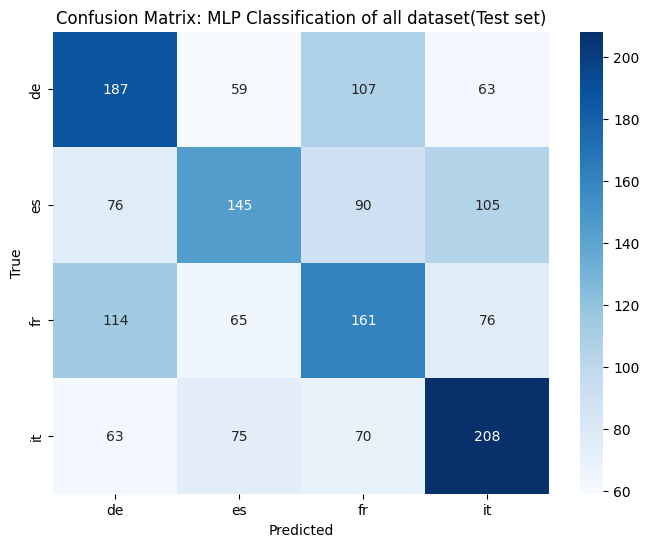

In [5]:
features = df.drop(columns=['L1',"dataset_name"]).select_dtypes(include=[np.number]).columns
#df = df.dropna()
mlp_model, acc, cm = run_nn(df, features, label_col="L1", title="MLP Classification of all dataset(Test set)")

#RQ2: Which language production type shows stronger shining-through?
One MLP per dataset (same setup as RQ1). Higher accuracy = the L1 is easier to recognise = stronger shining-through.

Length: 2080, Train: 1664, Test: 416



===== MLP Classification of L2 dataset(Test set) =====
Test Accuracy: 0.39663461538461536

Classification Report:
               precision    recall  f1-score   support

          de     0.3932    0.4423    0.4163       104
          es     0.4500    0.4327    0.4412       104
          fr     0.3373    0.2692    0.2995       104
          it     0.3966    0.4423    0.4182       104

    accuracy                         0.3966       416
   macro avg     0.3943    0.3966    0.3938       416
weighted avg     0.3943    0.3966    0.3938       416


Confusion matrix:
[[46 17 21 20]
 [16 45 17 26]
 [34 18 28 24]
 [21 20 17 46]]


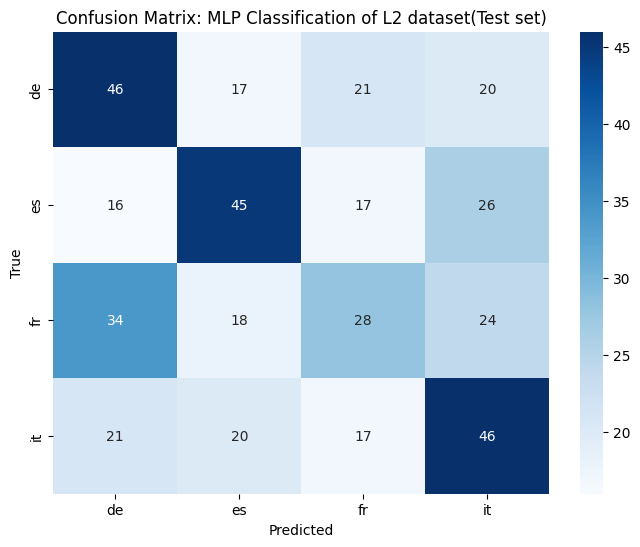

In [6]:
features = L2.drop(columns=['L1',"dataset_name"]).select_dtypes(include=[np.number]).columns
mlp_model, acc, cm = run_nn(L2, features, label_col="L1", title="MLP Classification of L2 dataset(Test set)")

Length: 2080, Train: 1664, Test: 416



===== MLP Classification of TR1 dataset(Test set) =====
Test Accuracy: 0.5456730769230769

Classification Report:
               precision    recall  f1-score   support

          de     0.5194    0.6442    0.5751       104
          es     0.3908    0.3269    0.3560       104
          fr     0.5604    0.4904    0.5231       104
          it     0.6881    0.7212    0.7042       104

    accuracy                         0.5457       416
   macro avg     0.5397    0.5457    0.5396       416
weighted avg     0.5397    0.5457    0.5396       416


Confusion matrix:
[[67 12 18  7]
 [36 34 15 19]
 [22 23 51  8]
 [ 4 18  7 75]]


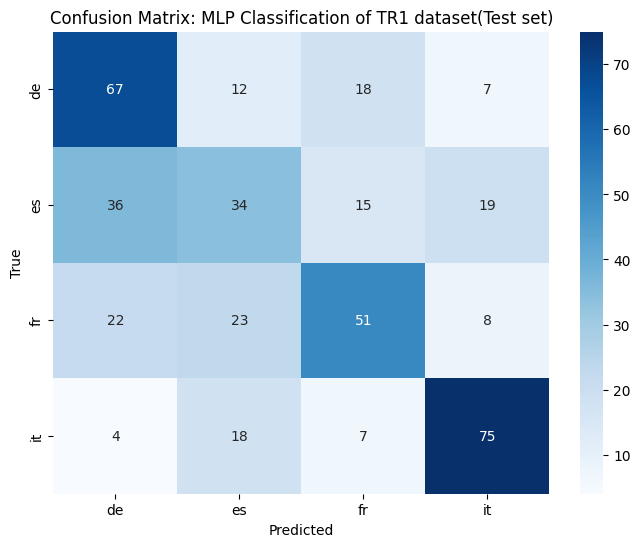

In [7]:
features = TR1.drop(columns=['L1',"dataset_name"]).select_dtypes(include=[np.number]).columns
TR1 = TR1.dropna()
mlp_model, acc, cm = run_nn(TR1, features, label_col="L1", title="MLP Classification of TR1 dataset(Test set)")

Length: 2080, Train: 1664, Test: 416

===== MLP Classification of TR2 dataset(Test set) =====
Test Accuracy: 0.3245192307692308

Classification Report:
               precision    recall  f1-score   support

          de     0.3151    0.4423    0.3680       104
          es     0.2639    0.1827    0.2159       104
          fr     0.2500    0.2019    0.2234       104
          it     0.4298    0.4712    0.4495       104

    accuracy                         0.3245       416
   macro avg     0.3147    0.3245    0.3142       416
weighted avg     0.3147    0.3245    0.3142       416


Confusion matrix:
[[46 23 21 14]
 [39 19 21 25]
 [41 16 21 26]
 [20 14 21 49]]


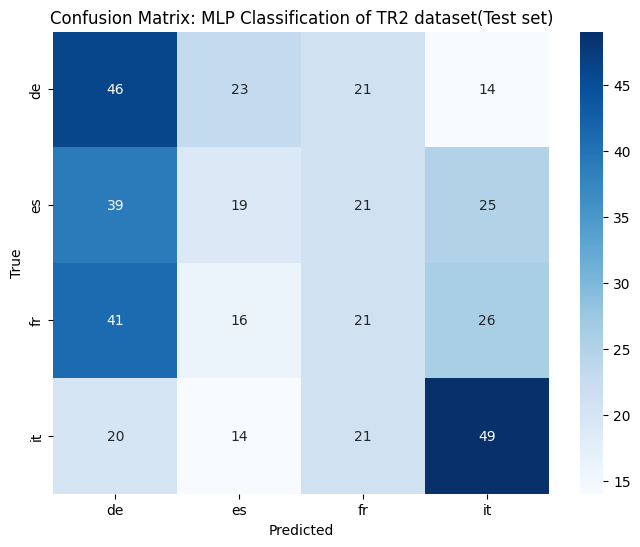

In [8]:
features = TR2.drop(columns=['L1',"dataset_name"]).select_dtypes(include=[np.number]).columns
mlp_model, acc, cm = run_nn(TR2, features, label_col="L1", title="MLP Classification of TR2 dataset(Test set)")

Length: 2080, Train: 1664, Test: 416



===== MLP Classification of NN dataset(Test set) =====
Test Accuracy: 0.5625

Classification Report:
               precision    recall  f1-score   support

          de     0.5283    0.5385    0.5333       104
          es     0.5714    0.6154    0.5926       104
          fr     0.5000    0.4904    0.4951       104
          it     0.6562    0.6058    0.6300       104

    accuracy                         0.5625       416
   macro avg     0.5640    0.5625    0.5628       416
weighted avg     0.5640    0.5625    0.5628       416


Confusion matrix:
[[56 10 31  7]
 [10 64 14 16]
 [28 15 51 10]
 [12 23  6 63]]


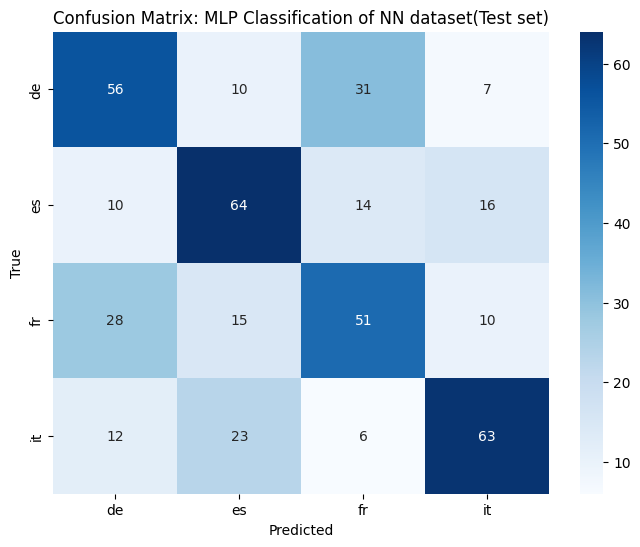

In [9]:
features = NN.drop(columns=['L1',"dataset_name"]).select_dtypes(include=[np.number]).columns
mlp_model, acc, cm = run_nn(NN, features, label_col="L1", title="MLP Classification of NN dataset(Test set)")

# RQ3: Train on one and test on others - NN
Train on all chunks of one dataset, test on all chunks of another. Accuracy near 0.25 = the L1 signal does not transfer.
- (L2 -> TR1)
- (L2 ->TR2)
- (L2 ->NN)
- (TR1 ->L2)
- (TR1 ->TR2)
- (TR1 ->NN)
- (TR2 ->L2)
- (TR2 ->TR1)
- (TR2 ->NN)
- (NN ->L2)
- (NN ->TR1)
- (NN ->TR2)

In [10]:
exclude_cols = ["L1", "dataset_name", "L1_num"]

features = [col for col in L2.columns if col not in exclude_cols]

In [11]:
# all datasets have 520 rows per L1 (smallest available: NN-fr)
TR1 = (
    TR1
    .groupby('L1', group_keys=False)
    .sample(n=520, random_state=42)
)

L2 = (
    L2
    .groupby('L1', group_keys=False)
    .sample(n=520, random_state=42)
)


TR2 = (
    TR2
    .groupby('L1', group_keys=False)
    .sample(n=520, random_state=42)
)

NN = (
    NN
    .groupby('L1', group_keys=False)
    .sample(n=520, random_state=42)
)
TR1["dataset_name"] = "TR1"
TR2["dataset_name"] = "TR2"
L2["dataset_name"] = "L2"
NN["dataset_name"] = "NN"


df = pd.concat([TR1, L2, TR2, NN], axis=0, ignore_index=True)

In [12]:
def train_one_test_one(
    train_df,
    test_df,
    features,
    label_col="L1",
    title="Cross Dataset NN",
    plot=True
):

    # -----------------------
    # 1. Split features/labels
    # -----------------------
    X_train = train_df[features].values
    y_train = train_df[label_col].values

    X_test = test_df[features].values
    y_test = test_df[label_col].values

    # -----------------------
    # 2. Label Encoding (fit ONLY on train)
    # -----------------------
    if y_train.dtype.kind in {'O', 'U', 'S'}:
        le = LabelEncoder()
        y_train = le.fit_transform(y_train)
        y_test = le.transform(y_test)
    else:
        le = None

    # -----------------------
    # 3. Handle NaNs (IMPORTANT)
    # -----------------------
    imputer = SimpleImputer(strategy="mean")
    X_train = imputer.fit_transform(X_train)
    X_test  = imputer.transform(X_test)

    # -----------------------
    # 4. Scaling (fit ONLY on train)
    # -----------------------
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test  = scaler.transform(X_test)

    # -----------------------
    # 5. Ensure dense float
    # -----------------------
    def to_dense_float(a):
        if sp.issparse(a):
            a = a.toarray()
        return np.asarray(a, dtype=np.float64)

    X_train = to_dense_float(X_train)
    X_test  = to_dense_float(X_test)

    y_train = np.asarray(y_train)
    y_test  = np.asarray(y_test)

    # -----------------------
    # 6. Model
    # -----------------------
    mlp = MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        max_iter=200,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=42
    )


    mlp.fit(X_train, y_train)

    # -----------------------
    # 7. Prediction
    # -----------------------
    y_pred = mlp.predict(X_test)

    # -----------------------
    # 8. Metrics
    # -----------------------
    accuracy = accuracy_score(y_test, y_pred)

    print(f"\n===== {title} =====")
    print("Test Accuracy:", accuracy)

    print("\nClassification Report:\n",
          classification_report(y_test, y_pred, digits=4, zero_division=0))

    # -----------------------
    # 9. Confusion Matrix (clean + aligned)
    # -----------------------
    labels = sorted(set(y_test) | set(y_pred))

    cm_df = pd.crosstab(
        y_test,
        y_pred,
        rownames=['True'],
        colnames=['Pred']
    ).reindex(index=labels, columns=labels, fill_value=0)

    # Optional: map labels to readable names
    if le is not None:
        class_names = le.inverse_transform(labels)
        cm_df.index = class_names
        cm_df.columns = class_names

    print("\nConfusion Matrix:\n", cm_df)

    # -----------------------
    # 10. Plot
    # -----------------------
    if plot:
        plt.figure(figsize=(8, 6))
        sns.heatmap(
            cm_df,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=cm_df.columns,
            yticklabels=cm_df.index
        )
        plt.title(f"Confusion Matrix: {title}")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.tight_layout()
        plt.show()

    return mlp, accuracy, cm_df


===== TR1 -> TR2 =====
Test Accuracy: 0.28942307692307695

Classification Report:
               precision    recall  f1-score   support

           0     0.3423    0.0731    0.1204       520
           1     0.2878    0.1135    0.1628       520
           2     0.2892    0.1808    0.2225       520
           3     0.2856    0.7904    0.4196       520

    accuracy                         0.2894      2080
   macro avg     0.3012    0.2894    0.2313      2080
weighted avg     0.3012    0.2894    0.2313      2080


Confusion Matrix:
     de  es   fr   it
de  38  41  116  325
es  27  59   82  352
fr  30  45   94  351
it  16  60   33  411


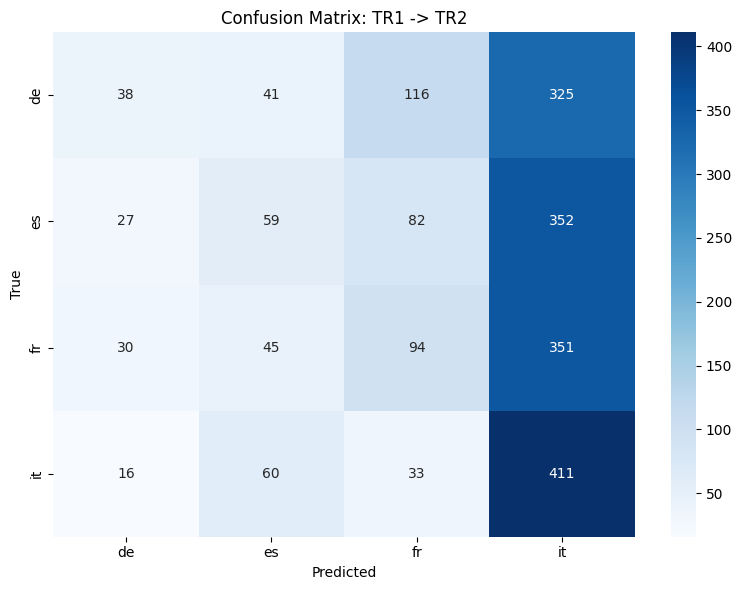

(MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32), random_state=42),
 0.28942307692307695,
     de  es   fr   it
 de  38  41  116  325
 es  27  59   82  352
 fr  30  45   94  351
 it  16  60   33  411)

In [13]:
train_one_test_one(
    TR1,
    TR2,
    features,
    title="TR1 -> TR2"
)


===== TR1 -> L2 =====
Test Accuracy: 0.2971153846153846

Classification Report:
               precision    recall  f1-score   support

           0     0.3568    0.1365    0.1975       520
           1     0.3053    0.1538    0.2046       520
           2     0.3107    0.4308    0.3610       520
           3     0.2706    0.4673    0.3427       520

    accuracy                         0.2971      2080
   macro avg     0.3109    0.2971    0.2765      2080
weighted avg     0.3109    0.2971    0.2765      2080


Confusion Matrix:
     de  es   fr   it
de  71  46  205  198
es  31  80  145  264
fr  49  54  224  193
it  48  82  147  243


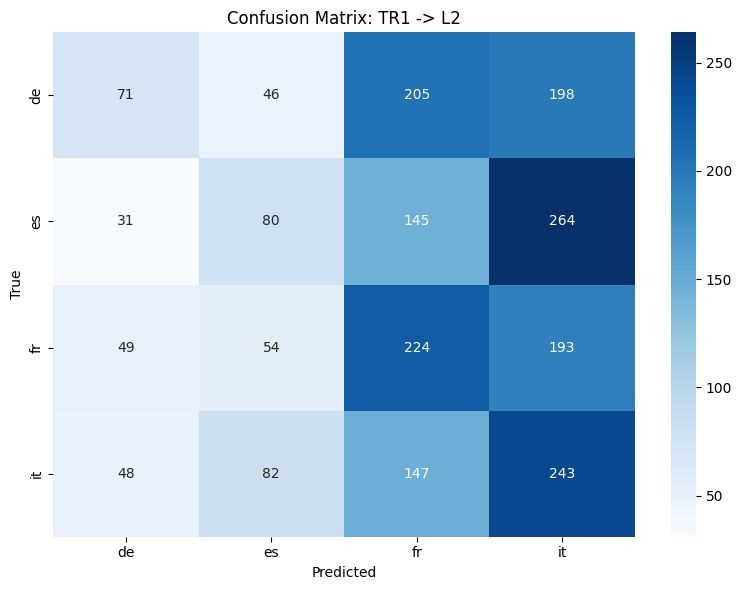

(MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32), random_state=42),
 0.2971153846153846,
     de  es   fr   it
 de  71  46  205  198
 es  31  80  145  264
 fr  49  54  224  193
 it  48  82  147  243)

In [14]:
train_one_test_one(
    TR1,
    L2,
    features,
    title="TR1 -> L2"
)


===== TR1 -> NN =====
Test Accuracy: 0.2389423076923077

Classification Report:
               precision    recall  f1-score   support

           0     0.2075    0.0423    0.0703       520
           1     0.3932    0.1558    0.2231       520
           2     0.2342    0.2500    0.2419       520
           3     0.2176    0.5077    0.3047       520

    accuracy                         0.2389      2080
   macro avg     0.2632    0.2389    0.2100      2080
weighted avg     0.2632    0.2389    0.2100      2080


Confusion Matrix:
     de  es   fr   it
de  22  31  146  321
es  41  81  110  288
fr  24  26  130  340
it  19  68  169  264


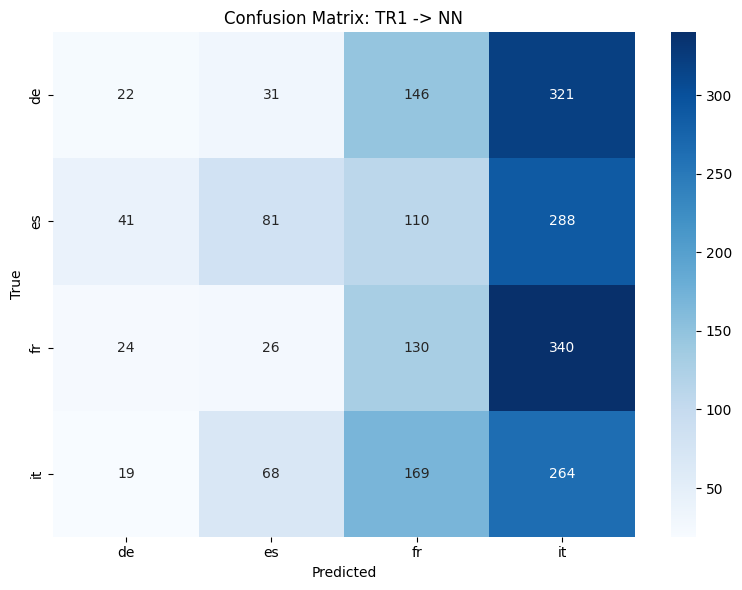

(MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32), random_state=42),
 0.2389423076923077,
     de  es   fr   it
 de  22  31  146  321
 es  41  81  110  288
 fr  24  26  130  340
 it  19  68  169  264)

In [15]:
train_one_test_one(
    TR1,
    NN,
    features,
    title="TR1 -> NN"
)


===== TR2 -> TR1 =====
Test Accuracy: 0.34807692307692306

Classification Report:
               precision    recall  f1-score   support

           0     0.4631    0.2654    0.3374       520
           1     0.3151    0.0885    0.1381       520
           2     0.3340    0.6173    0.4335       520
           3     0.3244    0.4212    0.3665       520

    accuracy                         0.3481      2080
   macro avg     0.3592    0.3481    0.3189      2080
weighted avg     0.3592    0.3481    0.3189      2080


Confusion Matrix:
      de  es   fr   it
de  138  38  205  139
es   58  46  203  213
fr   69  26  321  104
it   33  36  232  219


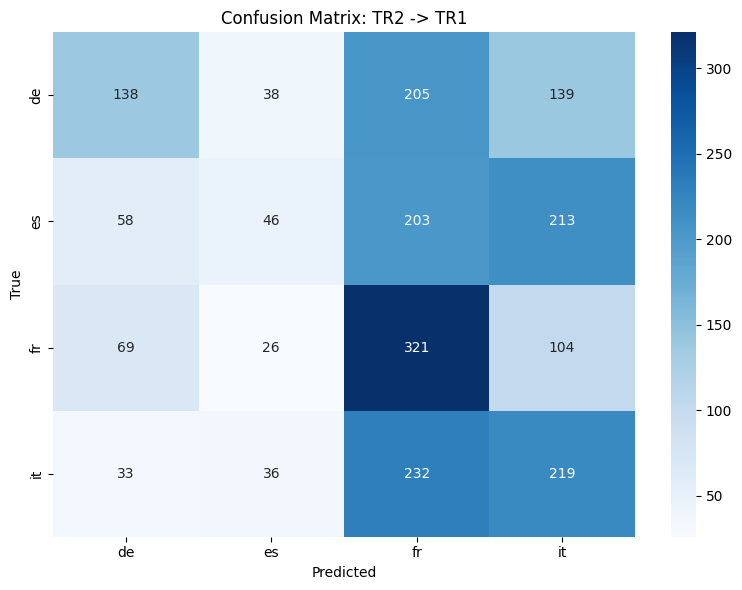

(MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32), random_state=42),
 0.34807692307692306,
      de  es   fr   it
 de  138  38  205  139
 es   58  46  203  213
 fr   69  26  321  104
 it   33  36  232  219)

In [16]:
train_one_test_one(
    TR2,
    TR1,
    features,
    title="TR2 -> TR1"
)


===== TR2 -> L2 =====
Test Accuracy: 0.2956730769230769

Classification Report:
               precision    recall  f1-score   support

           0     0.2780    0.5865    0.3772       520
           1     0.3299    0.1231    0.1793       520
           2     0.2785    0.2212    0.2465       520
           3     0.3484    0.2519    0.2924       520

    accuracy                         0.2957      2080
   macro avg     0.3087    0.2957    0.2739      2080
weighted avg     0.3087    0.2957    0.2739      2080


Confusion Matrix:
      de  es   fr   it
de  305  41  123   51
es  225  64   88  143
fr  320  34  115   51
it  247  55   87  131


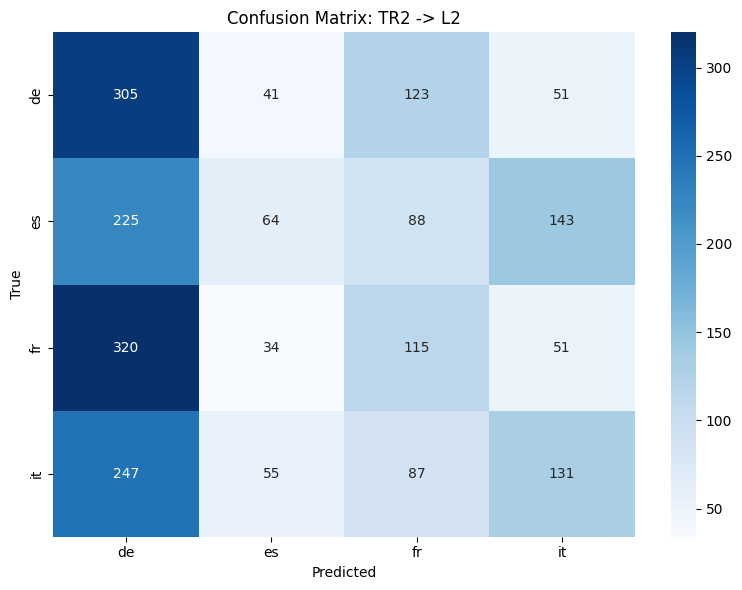

(MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32), random_state=42),
 0.2956730769230769,
      de  es   fr   it
 de  305  41  123   51
 es  225  64   88  143
 fr  320  34  115   51
 it  247  55   87  131)

In [17]:
train_one_test_one(
    TR2,
    L2,
    features,
    title="TR2 -> L2"
)


===== TR2 -> NN =====
Test Accuracy: 0.2778846153846154

Classification Report:
               precision    recall  f1-score   support

           0     0.3601    0.4827    0.4125       520
           1     0.2291    0.1212    0.1585       520
           2     0.2338    0.3327    0.2746       520
           3     0.2473    0.1750    0.2050       520

    accuracy                         0.2779      2080
   macro avg     0.2676    0.2779    0.2626      2080
weighted avg     0.2676    0.2779    0.2626      2080


Confusion Matrix:
      de  es   fr   it
de  251  61  140   68
es   95  63  211  151
fr  209  80  173   58
it  142  71  216   91


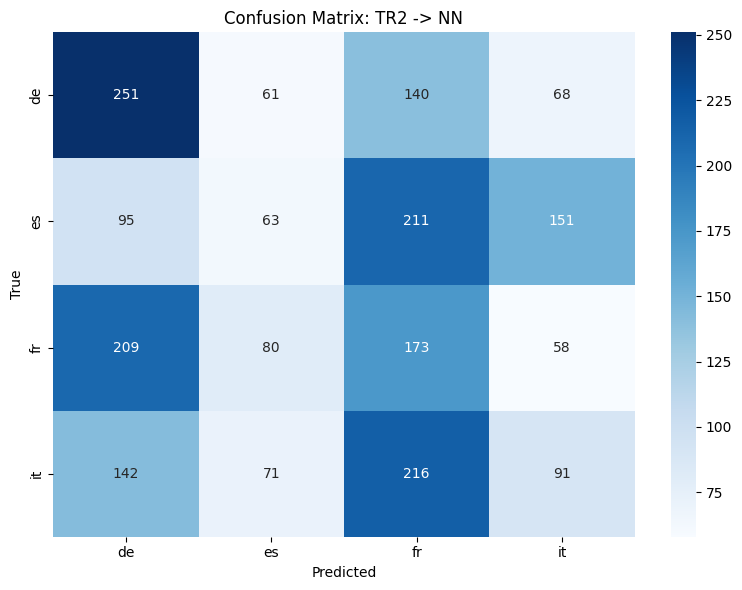

(MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32), random_state=42),
 0.2778846153846154,
      de  es   fr   it
 de  251  61  140   68
 es   95  63  211  151
 fr  209  80  173   58
 it  142  71  216   91)

In [18]:
train_one_test_one(
    TR2,
    NN,
    features,
    title="TR2 -> NN"
)


===== L2 -> TR1 =====
Test Accuracy: 0.30240384615384613

Classification Report:
               precision    recall  f1-score   support

           0     0.2931    0.8212    0.4320       520
           1     0.2672    0.0673    0.1075       520
           2     0.1857    0.0500    0.0788       520
           3     0.4006    0.2712    0.3234       520

    accuracy                         0.3024      2080
   macro avg     0.2866    0.3024    0.2354      2080
weighted avg     0.2866    0.3024    0.2354      2080


Confusion Matrix:
      de  es  fr   it
de  427   6  41   46
es  350  35  26  109
fr  422  16  26   56
it  258  74  47  141


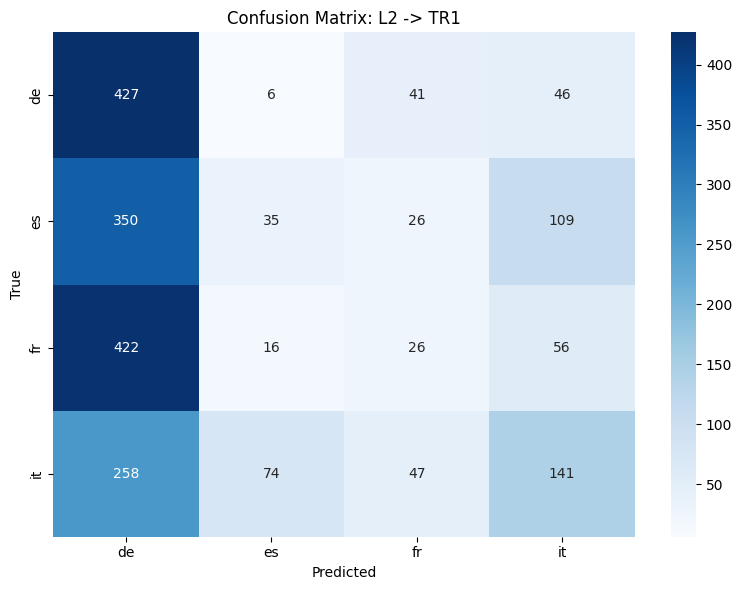

(MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32), random_state=42),
 0.30240384615384613,
      de  es  fr   it
 de  427   6  41   46
 es  350  35  26  109
 fr  422  16  26   56
 it  258  74  47  141)

In [19]:
train_one_test_one(
    L2,
    TR1,
    features,
    title="L2 -> TR1"
)


===== L2 -> TR2 =====
Test Accuracy: 0.29134615384615387

Classification Report:
               precision    recall  f1-score   support

           0     0.2749    0.2173    0.2427       520
           1     0.2541    0.1808    0.2112       520
           2     0.2864    0.2192    0.2484       520
           3     0.3163    0.5481    0.4011       520

    accuracy                         0.2913      2080
   macro avg     0.2829    0.2913    0.2759      2080
weighted avg     0.2829    0.2913    0.2759      2080


Confusion Matrix:
      de   es   fr   it
de  113   68  155  184
es  102   94   83  241
fr  124   91  114  191
it   72  117   46  285


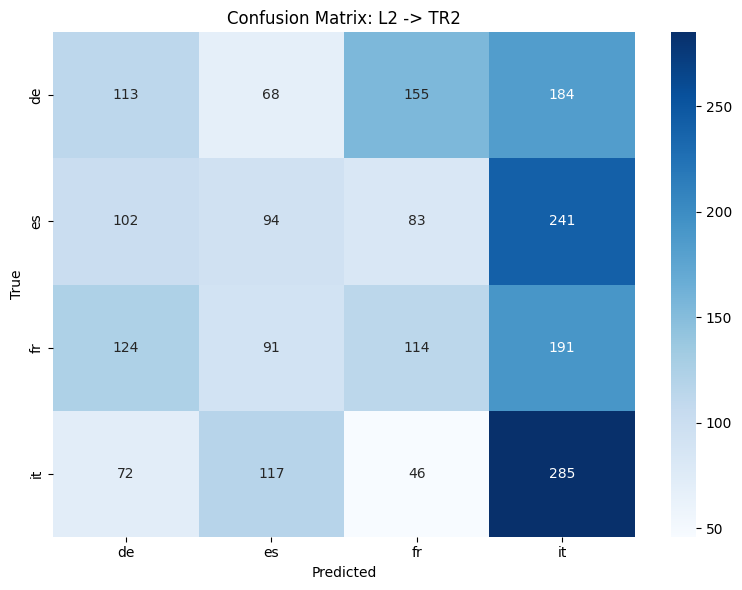

(MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32), random_state=42),
 0.29134615384615387,
      de   es   fr   it
 de  113   68  155  184
 es  102   94   83  241
 fr  124   91  114  191
 it   72  117   46  285)

In [20]:
train_one_test_one(
    L2,
    TR2,
    features,
    title="L2 -> TR2"
)


===== L2 -> NN =====
Test Accuracy: 0.25576923076923075

Classification Report:
               precision    recall  f1-score   support

           0     0.1547    0.1577    0.1562       520
           1     0.2056    0.1423    0.1682       520
           2     0.3482    0.3750    0.3611       520
           3     0.2873    0.3481    0.3148       520

    accuracy                         0.2558      2080
   macro avg     0.2489    0.2558    0.2501      2080
weighted avg     0.2489    0.2558    0.2501      2080


Confusion Matrix:
      de   es   fr   it
de   82  108  179  151
es  183   74   96  167
fr  100   94  195  131
it  165   84   90  181


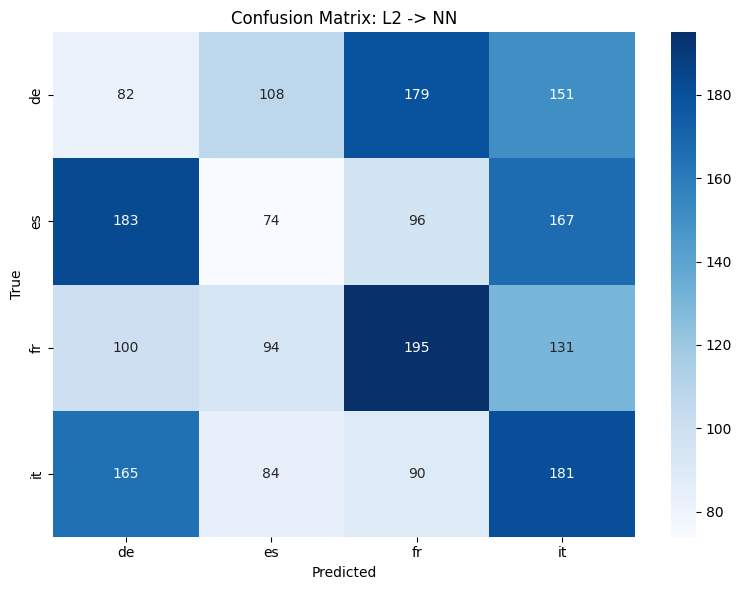

(MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32), random_state=42),
 0.25576923076923075,
      de   es   fr   it
 de   82  108  179  151
 es  183   74   96  167
 fr  100   94  195  131
 it  165   84   90  181)

In [21]:
train_one_test_one(
    L2,
    NN,
    features,
    title="L2 -> NN"
)


===== NN -> TR1 =====
Test Accuracy: 0.2605769230769231

Classification Report:
               precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000       520
           1     0.2600    0.9365    0.4070       520
           2     0.1333    0.0115    0.0212       520
           3     0.3267    0.0942    0.1463       520

    accuracy                         0.2606      2080
   macro avg     0.1800    0.2606    0.1436      2080
weighted avg     0.1800    0.2606    0.1436      2080


Confusion Matrix:
     de   es  fr  it
de   0  487  12  21
es   1  487   7  25
fr   3  456   6  55
it   8  443  20  49


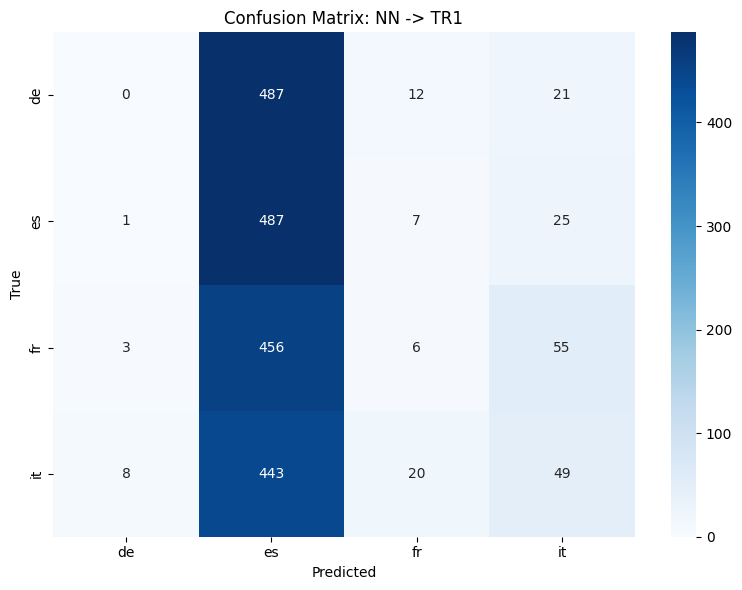

(MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32), random_state=42),
 0.2605769230769231,
     de   es  fr  it
 de   0  487  12  21
 es   1  487   7  25
 fr   3  456   6  55
 it   8  443  20  49)

In [22]:
train_one_test_one(
    NN,
    TR1,
    features,
    title="NN -> TR1"
)


===== NN -> TR2 =====
Test Accuracy: 0.25721153846153844

Classification Report:
               precision    recall  f1-score   support

           0     0.2939    0.2673    0.2800       520
           1     0.2216    0.2288    0.2252       520
           2     0.2710    0.2673    0.2691       520
           3     0.2478    0.2654    0.2563       520

    accuracy                         0.2572      2080
   macro avg     0.2585    0.2572    0.2576      2080
weighted avg     0.2585    0.2572    0.2576      2080


Confusion Matrix:
      de   es   fr   it
de  139  113  148  120
es  108  119  125  168
fr  128  122  139  131
it   98  183  101  138


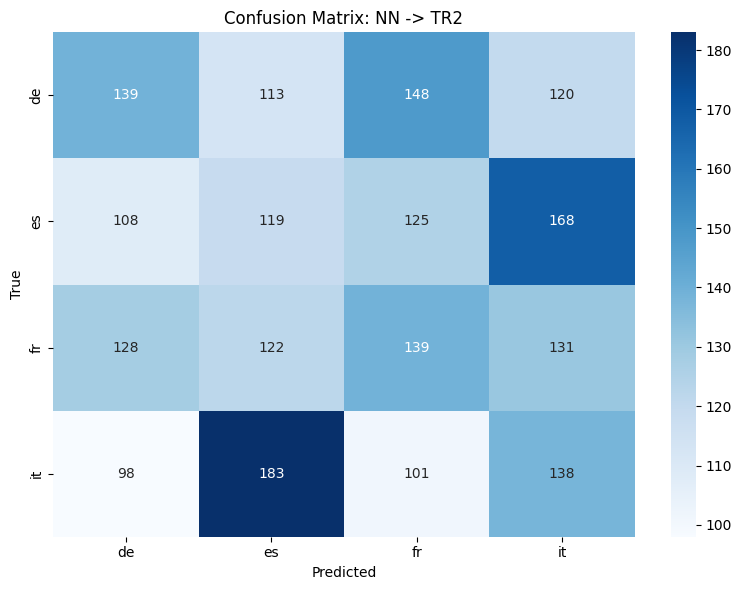

(MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32), random_state=42),
 0.25721153846153844,
      de   es   fr   it
 de  139  113  148  120
 es  108  119  125  168
 fr  128  122  139  131
 it   98  183  101  138)

In [23]:
train_one_test_one(
    NN,
    TR2,
    features,
    title="NN -> TR2"
)


===== NN -> L2 =====
Test Accuracy: 0.24326923076923077

Classification Report:
               precision    recall  f1-score   support

           0     0.2246    0.4635    0.3026       520
           1     0.1848    0.0327    0.0556       520
           2     0.2644    0.2288    0.2454       520
           3     0.2774    0.2481    0.2619       520

    accuracy                         0.2433      2080
   macro avg     0.2378    0.2433    0.2164      2080
weighted avg     0.2378    0.2433    0.2164      2080


Confusion Matrix:
      de  es   fr   it
de  241  30  116  133
es  281  17  114  108
fr  282  24  119   95
it  269  21  101  129


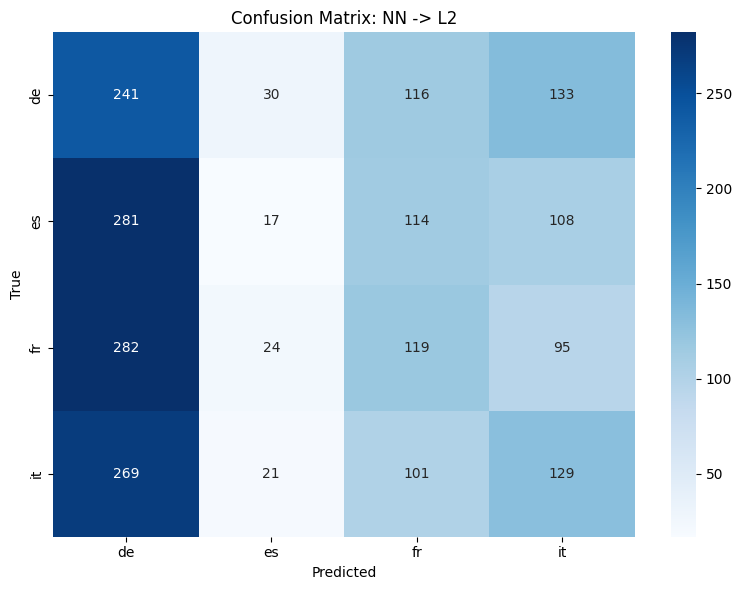

(MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32), random_state=42),
 0.24326923076923077,
      de  es   fr   it
 de  241  30  116  133
 es  281  17  114  108
 fr  282  24  119   95
 it  269  21  101  129)

In [24]:
train_one_test_one(
    NN,
    L2,
    features,
    title="NN -> L2"
)

# RQ4: Which variation dimension play a greater role – L1 or production type?
K-means on the standardised features; each cluster is mapped to its majority label and the clustering accuracy is computed.
* **Leave one language out, clusters vs L1**: k = 3 remaining languages (chance ≈ 0.33).
* **Leave one language out, clusters vs dataset**: k = 4 datasets (chance = 0.25).

If clustering matches the datasets much better than the L1s, production type is the stronger variation dimension.

In [25]:
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def run_kmeans_evaluation(df, n_clusters=None, label_col='L1', drop_cols=None, plot=True):

    #df = df.dropna().copy()

    # Separate labels
    y_true = df[label_col].values

    # Drop non-feature columns
    if drop_cols is not None:
        df_features = df.drop(drop_cols, axis=1)
    else:
        df_features = df.drop(columns=[label_col])

    X = df_features.values

    # SCALE FEATURES
    scaler = StandardScaler()
    X = scaler.fit_transform(X)

    # Auto-set clusters = number of classes if not given
    if n_clusters is None:
        n_clusters = len(np.unique(y_true))

    # Fit KMeans
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    cluster_ids = kmeans.fit_predict(X)

    df['cluster'] = cluster_ids

    cluster_to_label = {}

    for cluster in np.unique(cluster_ids):
        mask = (cluster_ids == cluster)

        if np.sum(mask) == 0:
            continue

        unique_labels, counts = np.unique(y_true[mask], return_counts=True)

        # Assign most frequent label
        cluster_to_label[cluster] = unique_labels[np.argmax(counts)]

    # Map predictions
    y_pred = np.array([cluster_to_label[c] for c in cluster_ids])

    # Accuracy
    accuracy = accuracy_score(y_true, y_pred)
    print("Clustering Accuracy:", accuracy)
    labels = sorted(set(y_true) | set(y_pred))

    confusion_matrix = pd.crosstab(
        y_true,
        y_pred,
        rownames=['True'],
        colnames=['Pred']
    ).reindex(index=labels, columns=labels, fill_value=0)
    print(confusion_matrix)

    print("\nClassification Report:\n",
          classification_report(y_true, y_pred, digits=4, zero_division=0))

    # Plot
    if plot:
        plt.figure(figsize=(8,6))
        sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Blues')
        plt.title(f'KMeans Confusion Matrix (k={n_clusters})')
        plt.show()

    df = df.drop('cluster', axis=1)

    return df, accuracy, confusion_matrix

In [26]:
def leave_one_language_out_kmeans(df, label_col='L1', drop_cols=None, plot=False):

    results = {}
    languages = df[label_col].unique()

    for lang in languages:
        print("\n" + "="*50)
        print(f"Removing language: {lang}")
        print("="*50)

        # Filter out one language
        df_subset = df[df[label_col] != lang].copy()

        # Run KMeans on remaining languages
        _, acc, cm = run_kmeans_evaluation(
            df_subset,
            n_clusters=len(languages) - 1,
            label_col=label_col,
            drop_cols=drop_cols,
            plot=plot
        )

        # Store results
        results[lang] = {
            "accuracy": acc,
            "confusion_matrix": cm
        }

    return results


Removing language: de


Clustering Accuracy: 0.40737179487179487
Pred   es    fr   it
True                
es    791   686  603
fr    642  1040  398
it    665   704  711

Classification Report:
               precision    recall  f1-score   support

          es     0.3770    0.3803    0.3787      2080
          fr     0.4280    0.5000    0.4612      2080
          it     0.4153    0.3418    0.3750      2080

    accuracy                         0.4074      6240
   macro avg     0.4068    0.4074    0.4049      6240
weighted avg     0.4068    0.4074    0.4049      6240



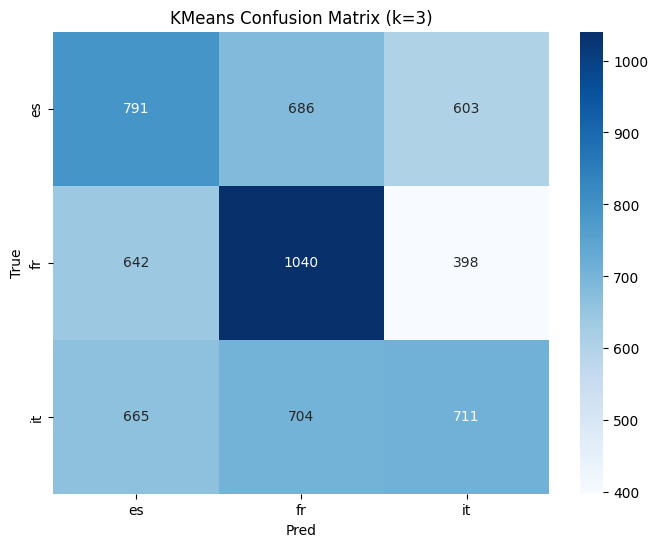


Removing language: es
Clustering Accuracy: 0.40400641025641026
Pred    de  fr    it
True                
de    1077   0  1003
fr     987   0  1093
it     636   0  1444

Classification Report:
               precision    recall  f1-score   support

          de     0.3989    0.5178    0.4506      2080
          fr     0.0000    0.0000    0.0000      2080
          it     0.4079    0.6942    0.5139      2080

    accuracy                         0.4040      6240
   macro avg     0.2689    0.4040    0.3215      6240
weighted avg     0.2689    0.4040    0.3215      6240



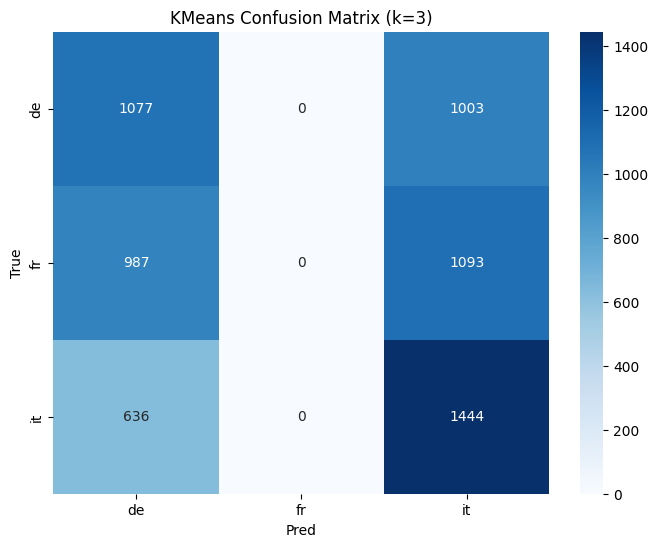


Removing language: fr
Clustering Accuracy: 0.4219551282051282
Pred    de   es   it
True                
de    1144  588  348
es     710  772  598
it     721  642  717

Classification Report:
               precision    recall  f1-score   support

          de     0.4443    0.5500    0.4915      2080
          es     0.3856    0.3712    0.3782      2080
          it     0.4311    0.3447    0.3831      2080

    accuracy                         0.4220      6240
   macro avg     0.4203    0.4220    0.4176      6240
weighted avg     0.4203    0.4220    0.4176      6240



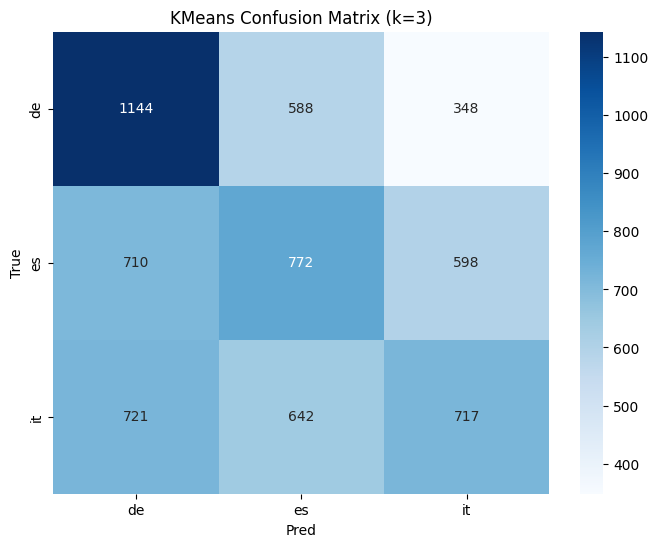


Removing language: it
Clustering Accuracy: 0.4060897435897436
Pred    de    es  fr
True                
de    1034  1046   0
es     580  1500   0
fr     948  1132   0



Classification Report:
               precision    recall  f1-score   support

          de     0.4036    0.4971    0.4455      2080
          es     0.4078    0.7212    0.5210      2080
          fr     0.0000    0.0000    0.0000      2080

    accuracy                         0.4061      6240
   macro avg     0.2705    0.4061    0.3222      6240
weighted avg     0.2705    0.4061    0.3222      6240



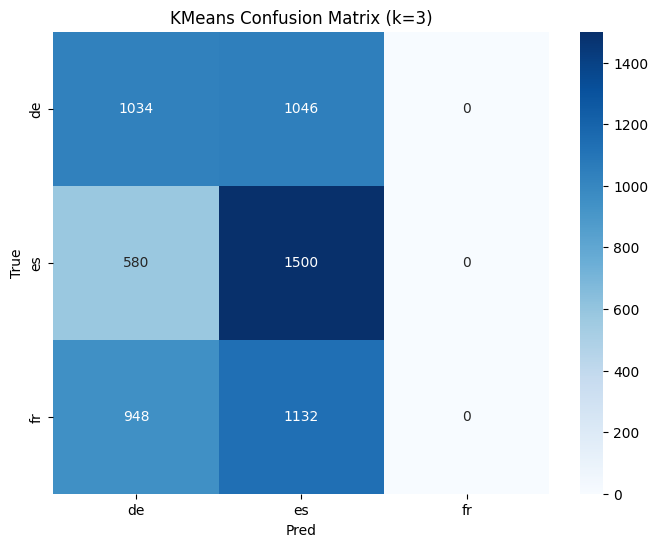

In [27]:
results = leave_one_language_out_kmeans(
df,
label_col='L1',
drop_cols=['L1',"dataset_name"],
plot=True
)


Removing language: de
Clustering Accuracy: 0.6532051282051282
Pred    L2   NN   TR1  TR2
True                      
L2    1062  397     6   95
NN     108  863   266  323
TR1      0  102  1393   65
TR2    173  553    76  758



Classification Report:
               precision    recall  f1-score   support

          L2     0.7908    0.6808    0.7317      1560
          NN     0.4507    0.5532    0.4967      1560
         TR1     0.8001    0.8929    0.8440      1560
         TR2     0.6108    0.4859    0.5412      1560

    accuracy                         0.6532      6240
   macro avg     0.6631    0.6532    0.6534      6240
weighted avg     0.6631    0.6532    0.6534      6240



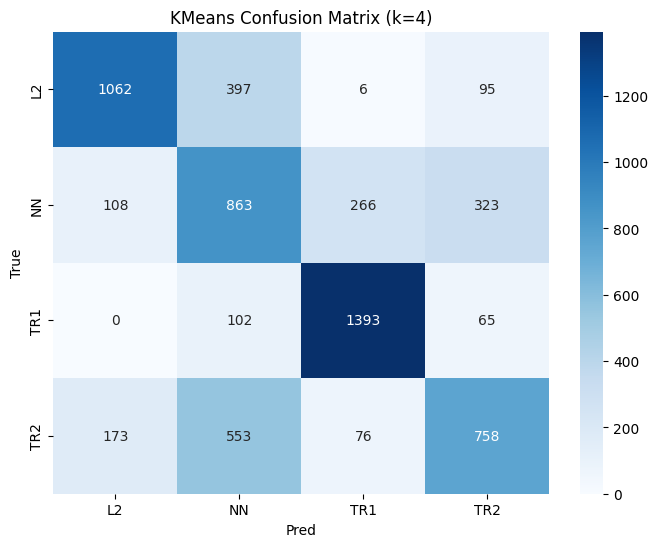


Removing language: es


Clustering Accuracy: 0.5368589743589743
Pred    L2  NN   TR1  TR2
True                     
L2    1054   0    45  461
NN     903   0   383  274
TR1     21   0  1522   17
TR2    534   0   252  774



Classification Report:
               precision    recall  f1-score   support

          L2     0.4196    0.6756    0.5177      1560
          NN     0.0000    0.0000    0.0000      1560
         TR1     0.6912    0.9756    0.8091      1560
         TR2     0.5072    0.4962    0.5016      1560

    accuracy                         0.5369      6240
   macro avg     0.4045    0.5369    0.4571      6240
weighted avg     0.4045    0.5369    0.4571      6240



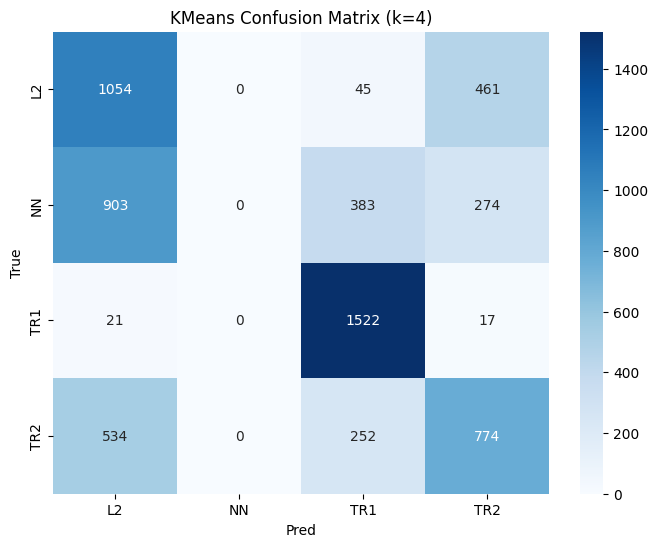


Removing language: fr
Clustering Accuracy: 0.5219551282051282
Pred   L2  NN   TR1  TR2
True                    
L2    997   0    31  532
NN    766   0   606  188
TR1    29   0  1520   11
TR2   574   0   246  740



Classification Report:
               precision    recall  f1-score   support

          L2     0.4214    0.6391    0.5079      1560
          NN     0.0000    0.0000    0.0000      1560
         TR1     0.6325    0.9744    0.7671      1560
         TR2     0.5031    0.4744    0.4883      1560

    accuracy                         0.5220      6240
   macro avg     0.3892    0.5220    0.4408      6240
weighted avg     0.3892    0.5220    0.4408      6240



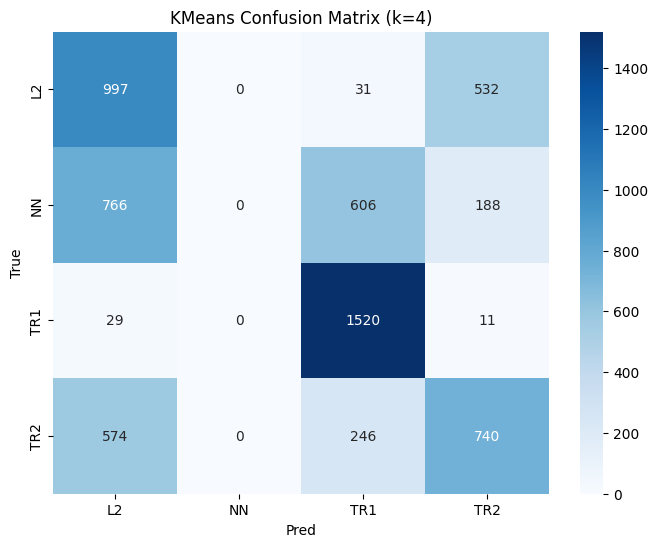


Removing language: it


Clustering Accuracy: 0.6504807692307693
Pred    L2   NN   TR1  TR2
True                      
L2    1005  423    11  121
NN     177  836   223  324
TR1      1   46  1486   27
TR2    139  606    83  732



Classification Report:
               precision    recall  f1-score   support

          L2     0.7602    0.6442    0.6974      1560
          NN     0.4375    0.5359    0.4817      1560
         TR1     0.8242    0.9526    0.8837      1560
         TR2     0.6080    0.4692    0.5297      1560

    accuracy                         0.6505      6240
   macro avg     0.6575    0.6505    0.6481      6240
weighted avg     0.6575    0.6505    0.6481      6240



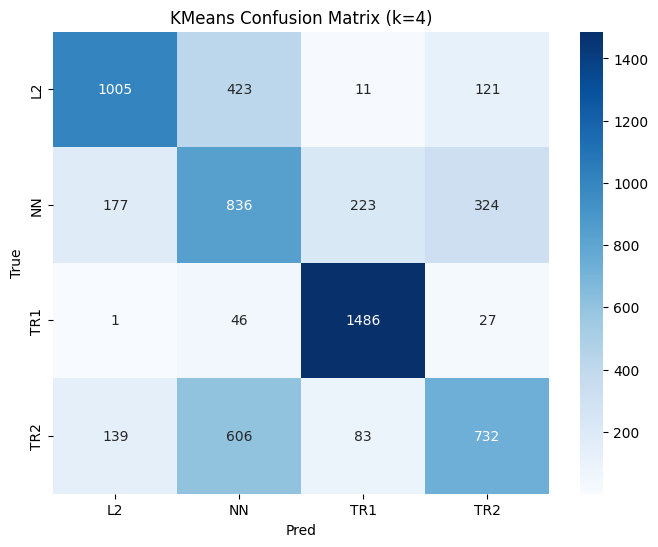

In [28]:
def leave_one_language_out_kmeans_dataset(df, label_col='L1', drop_cols=None, plot=False):

    results = {}
    languages = df[label_col].unique()

    for lang in languages:
        print("\n" + "="*50)
        print(f"Removing language: {lang}")
        print("="*50)

        # Filter out one language
        df_subset = df[df[label_col] != lang].copy()

        # Run KMeans on remaining languages
        _, acc, cm = run_kmeans_evaluation(
            df_subset,
            n_clusters = df_subset['dataset_name'].nunique(),
            label_col='dataset_name',
            drop_cols=drop_cols,
            plot=plot
        )

        # Store results
        results[lang] = {
            "accuracy": acc,
            "confusion_matrix": cm
        }

    return results


results = leave_one_language_out_kmeans_dataset(
df,
label_col='L1',
drop_cols=['L1',"dataset_name"],
plot=True
)

#RQ5: Which linguistic features contribute most to L1 identification and if they differ from those differentiating language products, i.e. general language variation indicators
SelectKBest (ANOVA F-test, k = 10) on all four datasets with the L1 as target. For every top-10 feature: a boxplot and a KDE plot over the 16 classes (dataset × L1), then the F-score bar chart. All plots are saved in `plots_SelectKBest/`.

In [29]:
num_cols = df.select_dtypes(include='number').columns
numerical_cols = [c for c in num_cols if c not in ['L1']]

print("Numeric feature columns:", numerical_cols)

Numeric feature columns: ['ppron', 'possdet', 'indef', 'cconj', 'whconj', 'relativ', 'pied', 'correl', 'copula', 'attrib', 'pasttense', 'lexdens', 'lexTTR', 'mquantif', 'mpred', 'finites', 'infs', 'pverbals', 'deverbals', 'bypassives', 'longpassives', 'sconj', 'addit', 'advers', 'caus', 'tempseq', 'epist', 'but', 'comp', 'sup', 'neg', 'numcls', 'simple', 'demdets', 'nnargs', 'mhd', 'mdd', 'acl', 'aux', 'aux:pass', 'ccomp', 'nsubj:pass', 'parataxis', 'xcomp']


In [30]:
l1_values = ["es", "de", "fr", "it"]
df_filtered = df[df["L1"].isin(l1_values)]

# Count of L1 per L2
count_per_L2 = df_filtered.groupby("dataset_name")["L1"].value_counts().unstack(fill_value=0)

print(count_per_L2)

L1             de   es   fr   it
dataset_name                    
L2            520  520  520  520
NN            520  520  520  520
TR1           520  520  520  520
TR2           520  520  520  520


In [31]:
df_balanced = df
to_drop = [c for c in ['L1','dataset_name','cluster','kmeans_labels'] if c in df_balanced.columns]
feature_cols = [c for c in df_balanced.columns if c not in to_drop]

df_balanced = df_balanced.dropna()
X_s = df_balanced[feature_cols].values
y_balanced = df_balanced['L1'].values  # target: L1

Top 10 features by ANOVA F-test: ['cconj', 'relativ', 'attrib', 'pverbals', 'sconj', 'numcls', 'simple', 'mhd', 'mdd', 'acl']


C:\Users\Khushi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [13] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
C:\Users\Khushi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


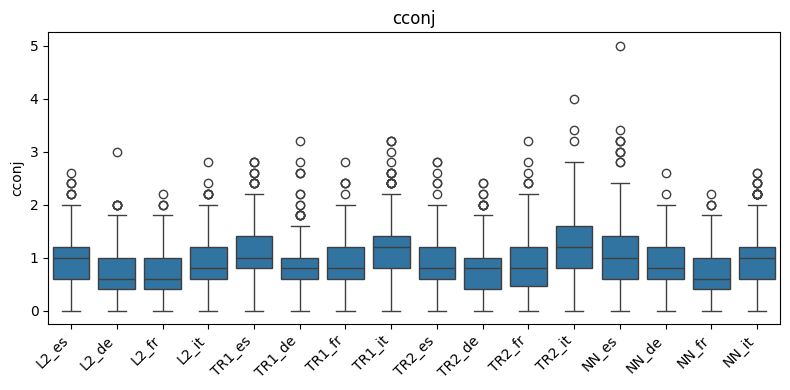

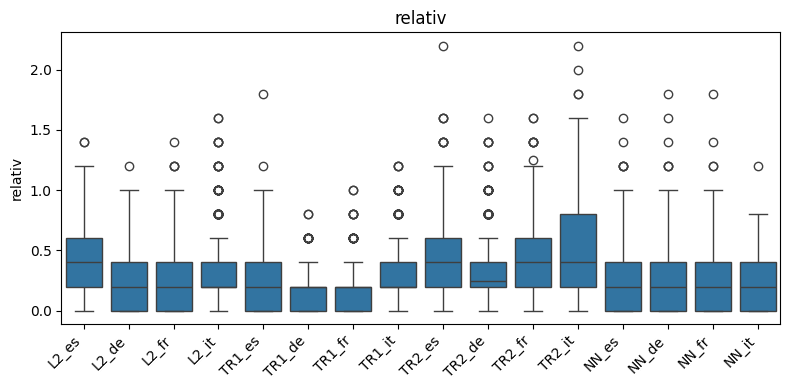

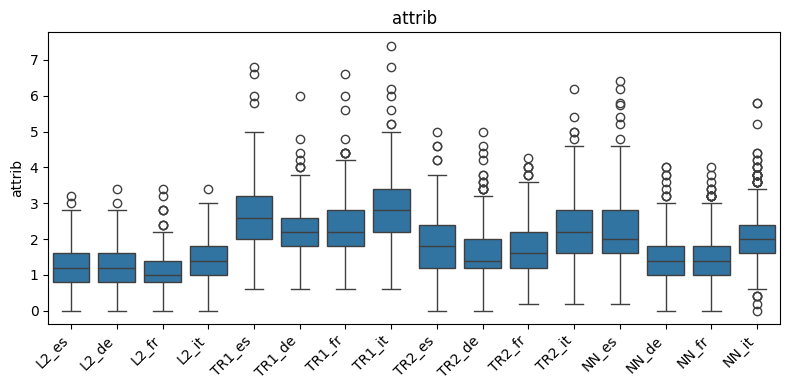

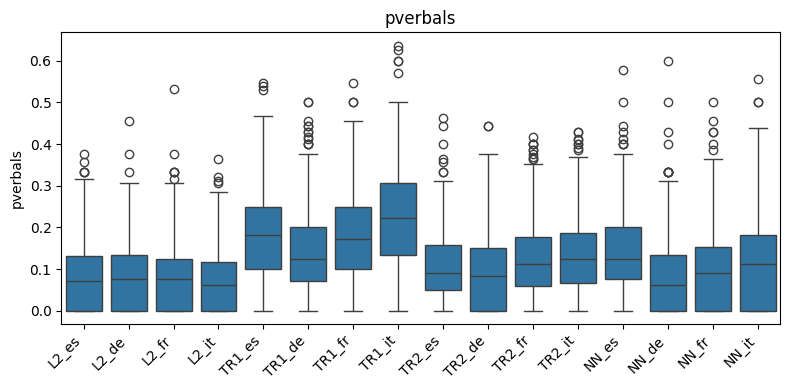

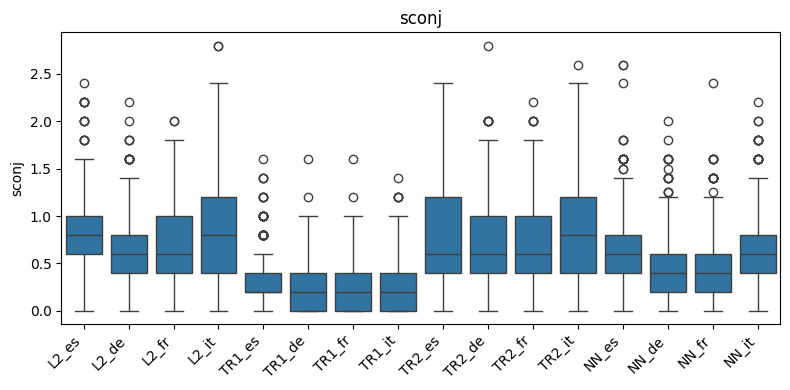

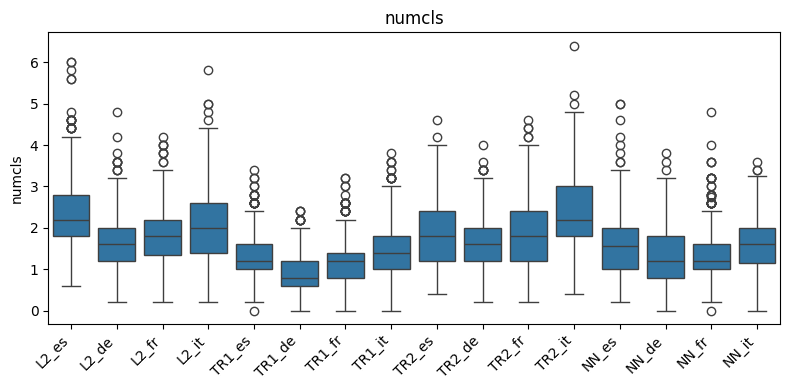

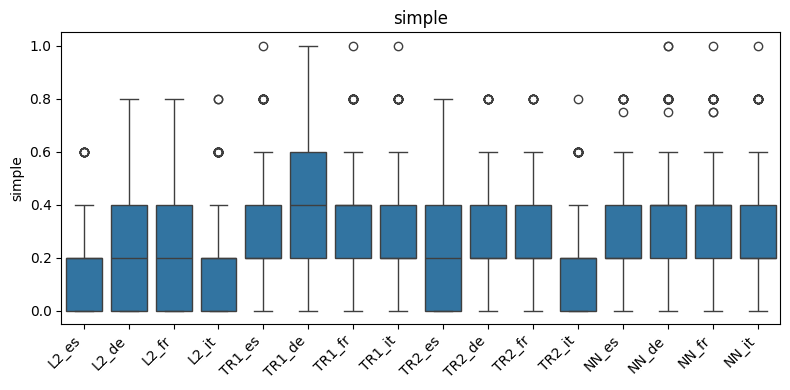

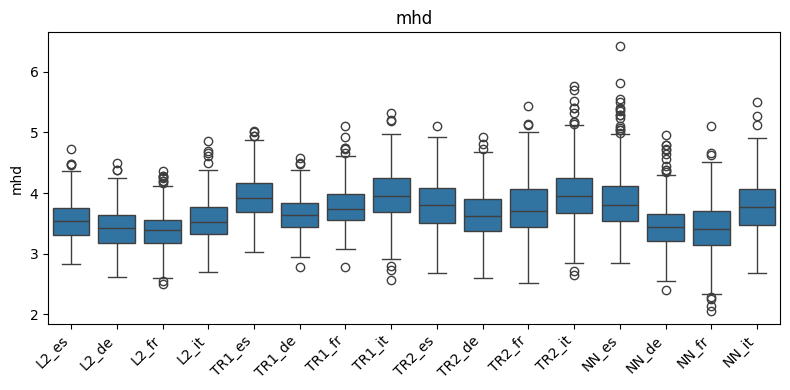

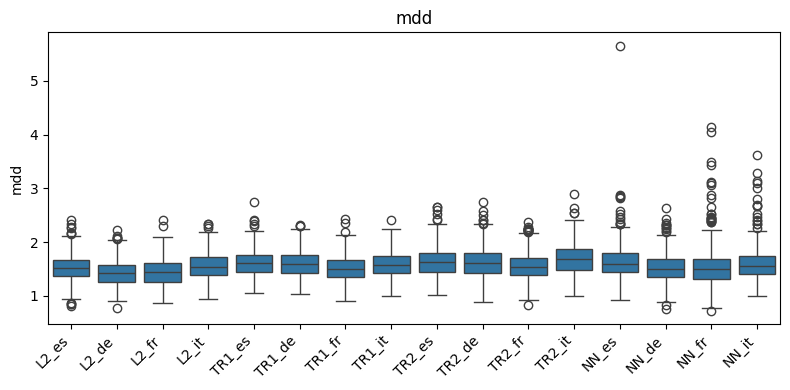

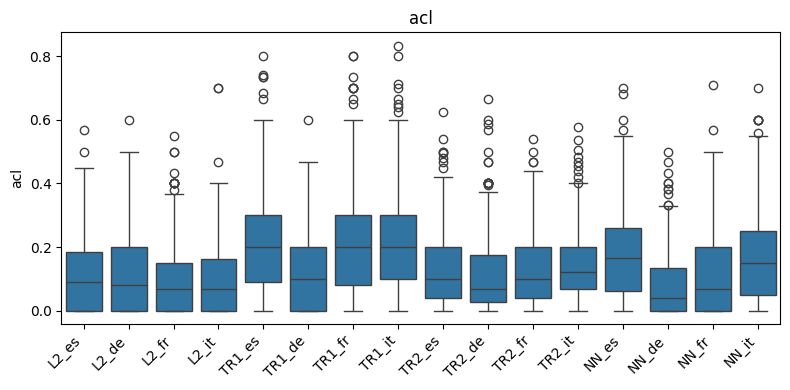

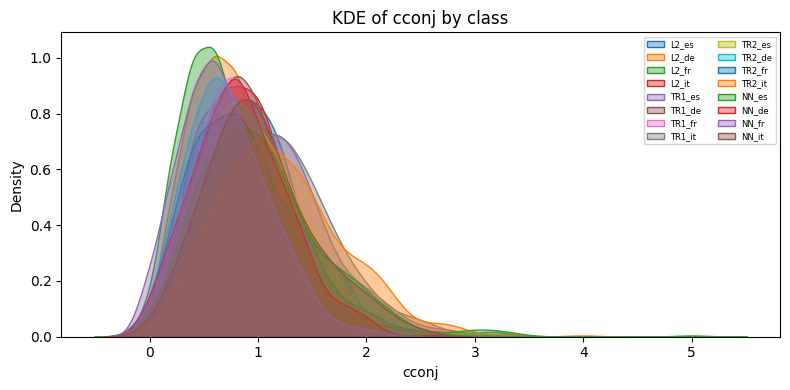

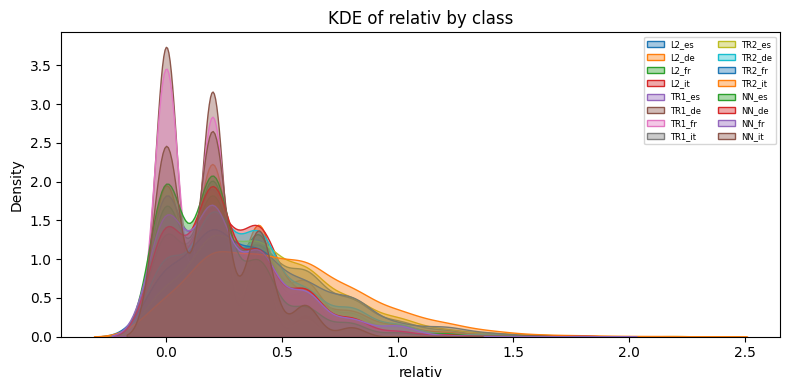

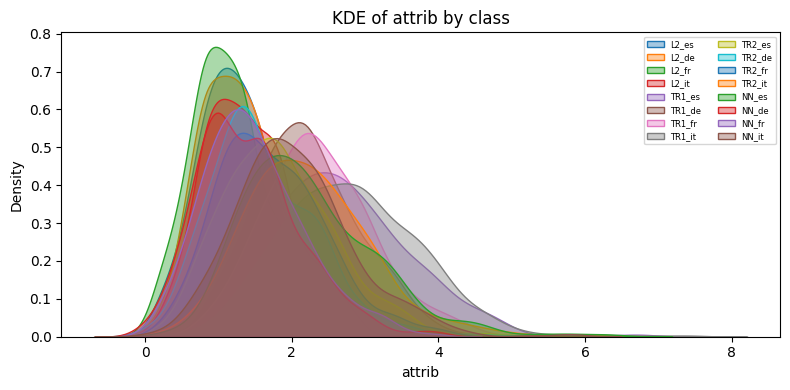

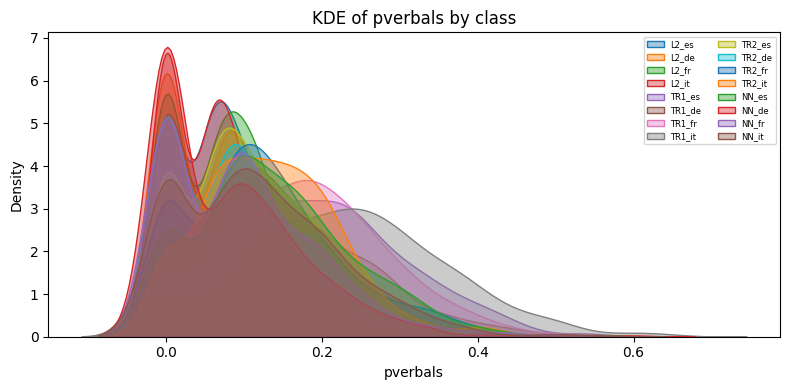

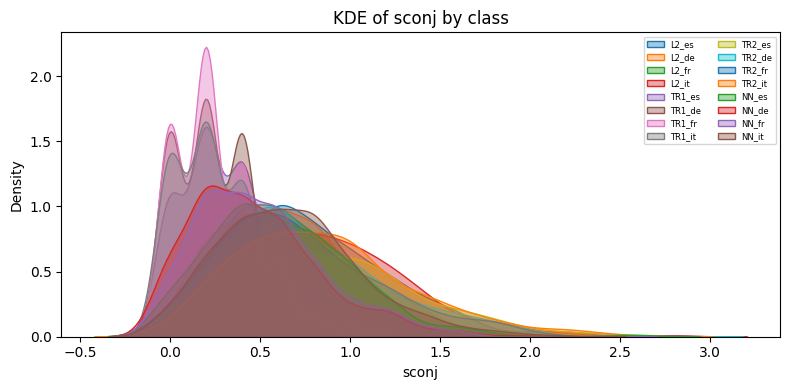

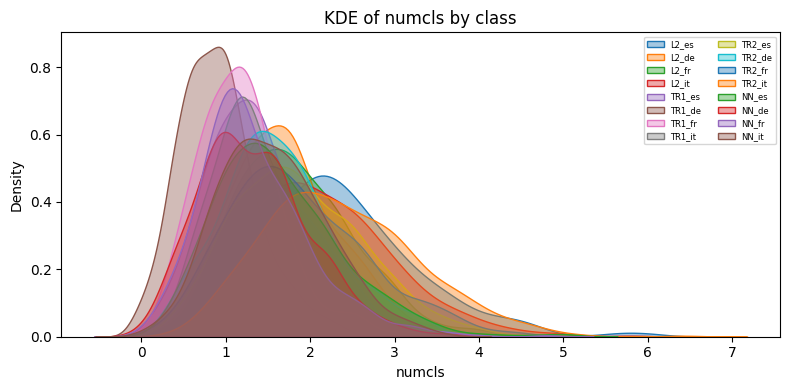

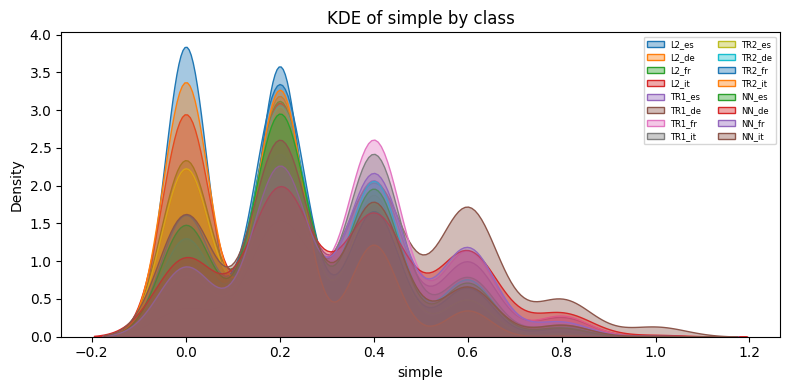

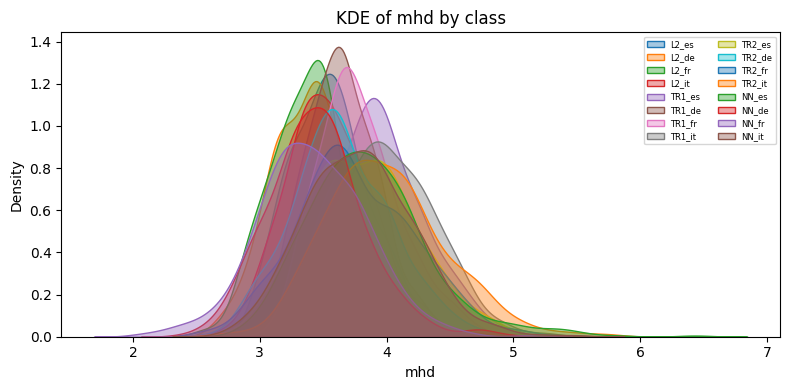

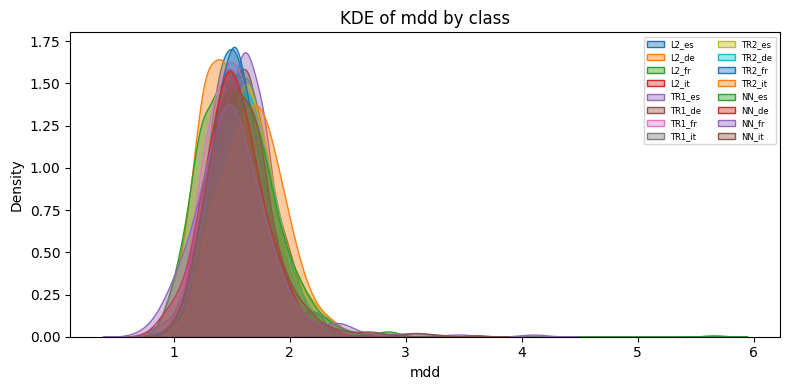

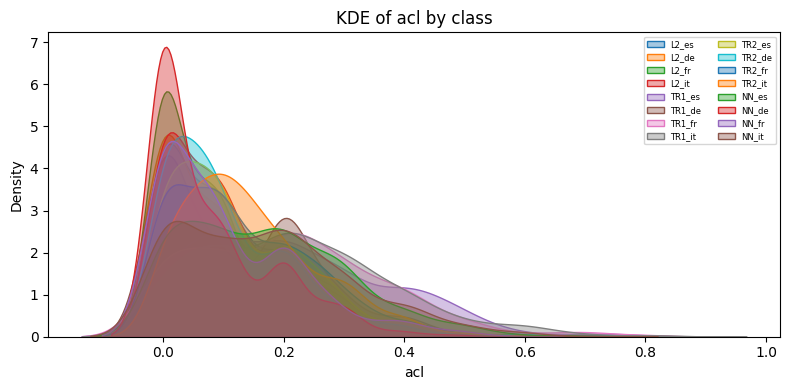

In [32]:
 # Required packages
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
import matplotlib.pyplot as plt
import os
#selectbest
selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X_s, y_balanced)
top_idx = selector.get_support(indices=True)
top10_SelectKBEST = [feature_cols[i] for i in top_idx]

print("Top 10 features by ANOVA F-test:", top10_SelectKBEST)

os.makedirs("plots_SelectKBest", exist_ok=True)

# create the 16-class column correctly
df_plot = df_balanced.copy()
df_plot['class'] = df_plot['dataset_name'].astype(str) + "_" + df_plot['L1'].astype(str)  # e.g. "L2_es"

# classes in correct order
classes = ["L2_es","L2_de","L2_fr","L2_it","TR1_es","TR1_de","TR1_fr","TR1_it",
           "TR2_es","TR2_de","TR2_fr","TR2_it","NN_es","NN_de","NN_fr","NN_it"]


# coerce features to numeric safely
for f in top10_SelectKBEST:
    df_plot[f] = pd.to_numeric(df_plot[f], errors='coerce')

# create plots and save individually
for feat in top10_SelectKBEST:
    plt.figure(figsize=(8,4))
    sns.boxplot(x='class', y=feat, data=df_plot, order=classes)
    plt.title(feat)
    plt.xlabel("")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()

    # save each feature individually
    plt.savefig(f"plots_SelectKBest/{feat}.png", dpi=300)
    plt.show()
    plt.close()   # important to avoid overlap


for feat in top10_SelectKBEST:
    plt.figure(figsize=(8,4))

    # KDE plot for all classes overlaid
    for cls in classes:
        subset = df_plot[df_plot['class'] == cls]
        if not subset.empty:
            sns.kdeplot(subset[feat], label=cls, fill=True, alpha=0.4)

    plt.title(f"KDE of {feat} by class")
    plt.xlabel(feat)
    plt.ylabel("Density")
    plt.legend(fontsize=6, ncol=2)
    plt.tight_layout()

    # save individually
    plt.savefig(f"plots_SelectKBest/{feat}_KDE.png", dpi=300)
    plt.show()
    plt.close()

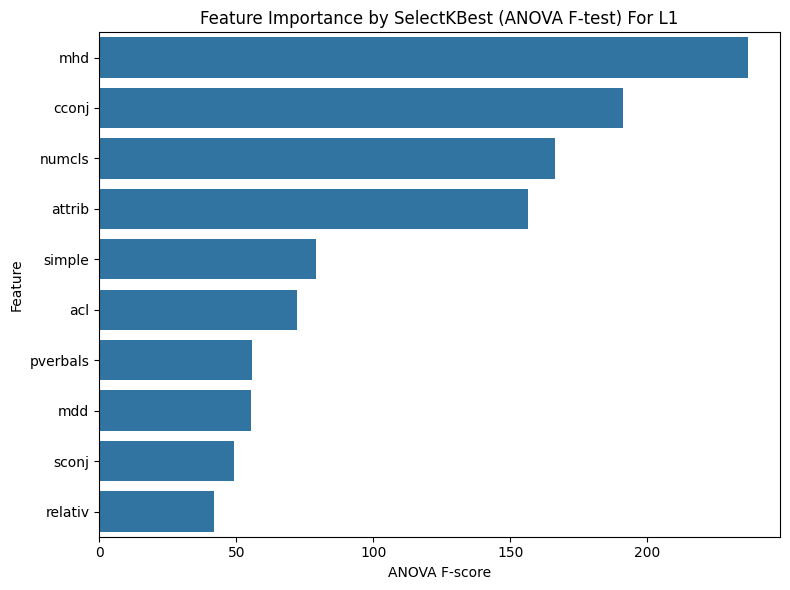

In [33]:
# Get the F-scores and p-values
f_scores = selector.scores_[top_idx]
p_values = selector.pvalues_[top_idx]

# Sort descending for horizontal bar plot
importance_df = pd.DataFrame({
    'Feature': top10_SelectKBEST,
    'F_score': f_scores,
    'p_value': p_values
}).sort_values(by='F_score', ascending=False)  # now highest F-score on top

# Plot horizontal bar plot
plt.figure(figsize=(8,6))
sns.barplot(x='F_score', y='Feature', data=importance_df)
plt.xlabel("ANOVA F-score")
plt.ylabel("Feature")
plt.title("Feature Importance by SelectKBest (ANOVA F-test) For L1")
plt.tight_layout()
plt.savefig("./plots_SelectKBest/Top10_Feature_Importance_desc.png", dpi=300)
plt.show()

In [34]:
import shutil
shutil.make_archive("plots_SelectKBest", "zip", ".", "plots_SelectKBest")

'C:\\Users\\Khushi\\Documents\\GitHub\\Shining-Through\\SSH\\Implementation\\plots_SelectKBest.zip'